# 05 – Baseline U-Net

Utilizziamo la U-Net originale del benchmark BRIGHT
come primo modello di riferimento per la segmentazione
multimodale dei danni agli edifici.

Verifichiamo inizialmente il funzionamento del modello
mediante un esperimento di overfitting su una singola
patch.

Successivamente addestriamo una nuova U-Net utilizzando
il campione operativo preparato nel notebook 04.

Valutiamo le prestazioni sul campione di validation
e analizziamo quantitativamente e qualitativamente
le previsioni ottenute.

In [1]:
from pathlib import Path
import sys
import torch

from bright_reproduction.models import crea_unet

ROOT = Path.cwd()
BRIGHT = ROOT / "BRIGHT"

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Interprete:", sys.executable)
print("Dispositivo:", device)
print("Directory:", ROOT)

Interprete: /Users/antonyogrossi/tesi/venv-tesi/bin/python
Dispositivo: mps
Directory: /Users/antonyogrossi/tesi/riproduzione_dfc2025


In [2]:
modello = crea_unet(BRIGHT).to(device)

num_parametri = sum(
    p.numel() for p in modello.parameters()
)

print("Modello:", type(modello).__name__)
print(f"Parametri: {num_parametri:,}")
print("Dispositivo:", next(modello.parameters()).device)

Modello: UNet
Parametri: 31,045,444
Dispositivo: mps:0


In [3]:
from bright_reproduction.data import BrightEsempiDataset
from torch.utils.data import DataLoader

CARTELLA_DATI = ROOT / "dati" / "bright_esempi"

identificativi = [
    "bata-explosion_00000049",
    "bata-explosion_00000014",
    "bata-explosion_00000047",
]

dataset = BrightEsempiDataset(
    CARTELLA_DATI,
    identificativi
)

loader = DataLoader(
    dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

batch = next(iter(loader))

print("Numero di esempi:", len(dataset))
print("Identificativo:", batch["id"])
print("Ottico:", batch["ottico"].shape)
print("SAR:", batch["sar"].shape)
print("Maschera:", batch["maschera"].shape)

Numero di esempi: 3
Identificativo: ['bata-explosion_00000049']
Ottico: torch.Size([1, 3, 1024, 1024])
SAR: torch.Size([1, 3, 1024, 1024])
Maschera: torch.Size([1, 1024, 1024])


In [4]:
from bright_reproduction.data import prepara_patch_centrale

DIM_PATCH = 128

input_modello, target, x, y = prepara_patch_centrale(
    batch,
    DIM_PATCH,
    device
)

print("Input:", input_modello.shape)
print("Target:", target.shape)
print("Classi presenti:", torch.unique(target).cpu().tolist())
print("Dispositivo:", input_modello.device)

Input: torch.Size([1, 6, 128, 128])
Target: torch.Size([1, 128, 128])
Classi presenti: [0, 3]
Dispositivo: mps:0


In [5]:
modello.eval()

with torch.no_grad():
    logits = modello(input_modello)

    previsione = torch.argmax(
        logits,
        dim=1
    )

print("Input:", input_modello.shape)
print("Logits:", logits.shape)
print("Previsione:", previsione.shape)
print("Classi predette:", torch.unique(previsione).cpu().tolist())
print("Logits finiti:", torch.isfinite(logits).all().item())

Input: torch.Size([1, 6, 128, 128])
Logits: torch.Size([1, 4, 128, 128])
Previsione: torch.Size([1, 128, 128])
Classi predette: [2]
Logits finiti: True


In [6]:
from bright_reproduction.data import prepara_target_loss

IGNORE_INDEX = 255

nome = batch["id"][0]

percorso_maschera = (
    CARTELLA_DATI / "target"
    / f"{nome}_building_damage.tif"
)

target_loss, nodata = prepara_target_loss(
    target,
    percorso_maschera,
    x,
    y,
    IGNORE_INDEX
)

print("NoData dichiarato:", nodata)
print("Pixel validi:", (target_loss != IGNORE_INDEX).sum().item())
print("Pixel ignorati:", (target_loss == IGNORE_INDEX).sum().item())

NoData dichiarato: None
Pixel validi: 16384
Pixel ignorati: 0


In [7]:
from torch import nn

criterio = nn.CrossEntropyLoss(
    ignore_index=IGNORE_INDEX
)

optimizer = torch.optim.AdamW(
    modello.parameters(),
    lr=1e-4
)

modello.train()

print("Loss:", type(criterio).__name__)
print("Optimizer:", type(optimizer).__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])

Loss: CrossEntropyLoss
Optimizer: AdamW
Learning rate: 0.0001


In [8]:
from bright_reproduction.training import training_step

parametro = next(modello.parameters())
pesi_prima = parametro.detach().clone()

loss = training_step(
    modello,
    input_modello,
    target_loss,
    criterio,
    optimizer
)

variazione = (
    parametro.detach() - pesi_prima
).abs().mean().item()

print("Loss:", loss)
print("Gradienti finiti:", torch.isfinite(parametro.grad).all().item())
print("Variazione media dei pesi:", variazione)
print("Pesi aggiornati:", variazione > 0)

Loss: 1.5569207668304443
Gradienti finiti: True
Variazione media dei pesi: 0.00010000043403124437
Pesi aggiornati: True


## Addestramento di prova su una singola patch

L'obiettivo di questo esperimento è verificare
la capacità della U-Net di apprendere ripetutamente
dalla stessa coppia di immagini ottiche e SAR.

Si tratta di un test tecnico di overfitting,
non di una valutazione della capacità
di generalizzazione del modello.

In [9]:
from bright_reproduction.training import addestra_su_patch

NUM_ITERAZIONI = 30

storico_loss = addestra_su_patch(
    modello,
    input_modello,
    target_loss,
    criterio,
    optimizer,
    NUM_ITERAZIONI
)

print("Iterazioni:", len(storico_loss))
print("Loss iniziale:", storico_loss[0])
print("Loss finale:", storico_loss[-1])
print("Loss minima:", min(storico_loss))

Iterazioni: 30
Loss iniziale: 1.4216725826263428
Loss finale: 0.5988259315490723
Loss minima: 0.5988259315490723


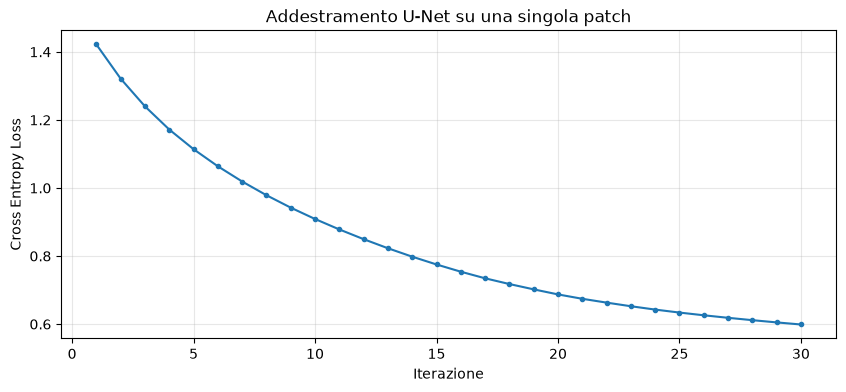

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.plot(
    range(1, len(storico_loss) + 1),
    storico_loss,
    marker="."
)

plt.xlabel("Iterazione")
plt.ylabel("Cross Entropy Loss")
plt.title("Addestramento U-Net su una singola patch")
plt.grid(alpha=0.3)
plt.show()

## Visualizzazione della previsione dopo l'addestramento

Confrontiamo la previsione della U-Net con la
maschera reale della patch utilizzata durante
l'addestramento.

L'obiettivo è verificare qualitativamente se il
modello riesce a riconoscere lo sfondo e gli
edifici distrutti.

Non si tratta di una valutazione su dati indipendenti.

In [11]:
modello.eval()

with torch.no_grad():

    logits_finali = modello(input_modello)

    previsione_finale = torch.argmax(
        logits_finali,
        dim=1
    )

    loss_eval = criterio(
        logits_finali,
        target_loss
    ).item()

print("Dimensioni:", previsione_finale.shape)
print("Classi predette:", torch.unique(previsione_finale).cpu().tolist())
print("Loss in modalità eval:", loss_eval)

Dimensioni: torch.Size([1, 128, 128])
Classi predette: [0, 1, 2, 3]
Loss in modalità eval: 1.0284428596496582


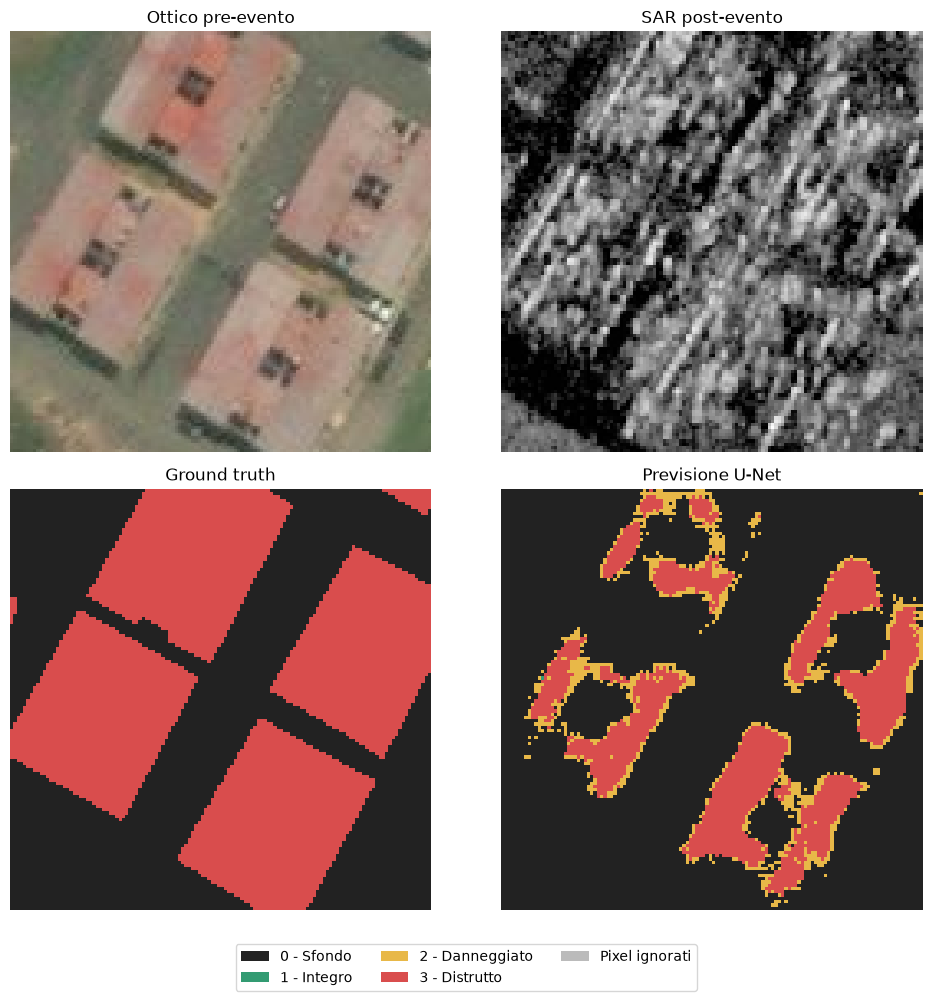

In [12]:
from bright_reproduction.visualization import (
    visualizza_previsione_patch
)

fig = visualizza_previsione_patch(
    input_modello,
    target_loss,
    previsione_finale
)

plt.show()

## Valutazione quantitativa della previsione

Utilizziamo le metriche implementate nel notebook 03
per valutare la previsione della U-Net sulla patch
di addestramento.

Confrontiamo il modello con una previsione di
controllo che assegna tutti i pixel allo sfondo.

Le metriche sono diagnostiche e non rappresentano
il punteggio ufficiale del DFC2025 Track 2.

In [13]:
from bright_reproduction.metriche import valuta_previsione

import numpy as np
import pandas as pd

riferimento = target_loss.cpu().numpy()
predizione = previsione_finale.cpu().numpy()

matrice, tabella, riepilogo = valuta_previsione(
    riferimento,
    predizione,
    IGNORE_INDEX
)

display(tabella.round(4))

print("Matrice di confusione:")
print(matrice)

,Pixel reali,Pixel predetti,IoU,F1
Classe,,,,
Sfondo,8195,12428,0.6525,0.7897
Integro,0,1,0.0000,0.0000
Danneggiato,0,1108,0.0000,0.0000
Distrutto,8189,2847,0.3465,0.5147


Matrice di confusione:
[[8143    0   45    7]
 [   0    0    0    0]
 [   0    0    0    0]
 [4285    1 1063 2840]]


In [14]:
sempre_sfondo = np.zeros_like(riferimento)

_, tabella_sfondo, riepilogo_sfondo = valuta_previsione(
    riferimento,
    sempre_sfondo,
    IGNORE_INDEX
)

confronto = pd.DataFrame({
    "U-Net": riepilogo,
    "Sempre sfondo": riepilogo_sfondo
}).T

display((confronto * 100).round(2))

,Accuracy,mIoU diagnostica,mIoU 4 classi,mIoU classi presenti,F1 edificio
U-Net,67.03,24.97,24.97,49.95,64.29
Sempre sfondo,50.02,25.01,12.50,25.01,0.00


## Salvataggio del checkpoint

Salviamo il modello ottenuto dopo 31 aggiornamenti
dei pesi sulla singola patch di addestramento.

Il checkpoint rappresenta un esperimento tecnico
preliminare di overfitting e non un modello
validato su dati indipendenti.

In [15]:
import subprocess
import bright_reproduction.training as training

configurazione = {
    "modello": "UNet BRIGHT",
    "in_channels": 6,
    "num_classes": 4,
    "device": str(device),
    "seed": 42,
    "batch_size": 1,
    "patch_size": DIM_PATCH,
    "patch_x": x,
    "patch_y": y,
    "learning_rate": optimizer.param_groups[0]["lr"],
    "optimizer": "AdamW",
    "loss": "CrossEntropyLoss",
    "ignore_index": IGNORE_INDEX,
    "train_id": nome,
    "training_steps": NUM_ITERAZIONI + 1,
    "torch_version": str(torch.__version__),
    "commit_progetto_base": subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        cwd=ROOT,
        text=True
    ).strip(),
    "commit_bright": subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        cwd=BRIGHT,
        text=True
    ).strip(),
    "tipo_esperimento": "overfitting_singola_patch"
}

percorso_checkpoint = training.salva_checkpoint(
    ROOT / "checkpoints" / "unet_overfit_patch.pt",
    modello,
    optimizer,
    configurazione,
    storico_loss
)

print("Checkpoint salvato:", percorso_checkpoint)

print(
    "Dimensione:",
    round(percorso_checkpoint.stat().st_size / 1024**2, 2),
    "MiB"
)

Checkpoint salvato: /Users/antonyogrossi/tesi/riproduzione_dfc2025/checkpoints/unet_overfit_patch.pt
Dimensione: 355.44 MiB


In [16]:
checkpoint = torch.load(
    percorso_checkpoint,
    map_location="cpu",
    weights_only=True
)

modello_caricato = crea_unet(BRIGHT)

modello_caricato.load_state_dict(
    checkpoint["model_state_dict"]
)

modello_caricato = modello_caricato.to(device)
modello_caricato.eval()

with torch.no_grad():
    logits_caricati = modello_caricato(input_modello)

    previsione_caricata = logits_caricati.argmax(dim=1)

print(
    "Previsioni identiche:",
    torch.equal(previsione_finale, previsione_caricata)
)

print(
    "Logits equivalenti:",
    torch.allclose(logits_finali, logits_caricati)
)

Previsioni identiche: True
Logits equivalenti: True


## Caricamento del campione sperimentale

Recuperiamo gli identificativi e la configurazione
salvati nel notebook 04.

Ricostruiamo i Dataset mantenendo invariati il campione,
l'ordine degli esempi, la dimensione delle patch e il
criterio di validità dei pixel.

In [17]:
import json

from bright_reproduction.data import BrightPatchDataset

CARTELLA_BASELINE = (
    ROOT / "dati" / "bright_baseline"
)

CARTELLA_SPLIT_OPERATIVI = (
    ROOT / "risultati" / "04_baseline_unet" / "splits"
)

configurazione_dati = json.loads(
    (
        CARTELLA_SPLIT_OPERATIVI
        / "configurazione_dati.json"
    ).read_text(encoding="utf-8")
)

campione_operativo = {
    split: (
        CARTELLA_SPLIT_OPERATIVI
        / f"campione_{split}.txt"
    ).read_text(encoding="utf-8").splitlines()

    for split in ["train", "val"]
}

DIM_PATCH_BASELINE = configurazione_dati["patch_size"]
TOLLERANZA_GRIGLIE = configurazione_dati["tolleranza_griglie"]

colonne_classi = [
    "sfondo",
    "integro",
    "danneggiato",
    "distrutto"
]

dataset_train = BrightPatchDataset(
    CARTELLA_BASELINE / "train",
    campione_operativo["train"],
    dimensione=DIM_PATCH_BASELINE,
    training=True,
    ignore_index=configurazione_dati["ignore_index"]
)

dataset_val = BrightPatchDataset(
    CARTELLA_BASELINE / "val",
    campione_operativo["val"],
    dimensione=DIM_PATCH_BASELINE,
    training=False,
    ignore_index=configurazione_dati["ignore_index"]
)

assert not (
    set(campione_operativo["train"])
    & set(campione_operativo["val"])
)

assert len(dataset_train) == configurazione_dati["patch_train"]
assert len(dataset_val) == configurazione_dati["patch_val"]

print("Immagini training:", len(campione_operativo["train"]))
print("Immagini validation:", len(campione_operativo["val"]))
print("Patch training:", len(dataset_train))
print("Patch validation:", len(dataset_val))

print("Dataset ricostruiti correttamente.")


Immagini training: 18
Immagini validation: 9
Patch training: 1017
Patch validation: 576
Dataset ricostruiti correttamente.


## Creazione dei DataLoader

Configuriamo i DataLoader per il training e
la validation utilizzando le patch preparate
dal package bright_reproduction.

Nel training utilizziamo uno shuffle
riproducibile, mentre nella validation
manteniamo l'ordine originale delle patch.

La prima baseline utilizza un campionamento
uniforme, senza pesatura delle classi.

In [18]:
from torch.utils.data import DataLoader

BATCH_SIZE = 4
SEED_BASELINE = 42

generatore_train = torch.Generator()
generatore_train.manual_seed(SEED_BASELINE)

loader_train = DataLoader(
    dataset_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=generatore_train
)

loader_val = DataLoader(
    dataset_val,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Batch size:", BATCH_SIZE)

print("Patch training:", len(dataset_train))
print("Batch training:", len(loader_train))

print("Patch validation:", len(dataset_val))
print("Batch validation:", len(loader_val))

Batch size: 4
Patch training: 1017
Batch training: 255
Patch validation: 576
Batch validation: 144


In [19]:
batch_test = next(iter(loader_train))

inputs_test = batch_test["input"].to(device)
targets_test = batch_test["target"].to(device)

print("Input:", inputs_test.shape)
print("Target:", targets_test.shape)

print("Tipo input:", inputs_test.dtype)
print("Tipo target:", targets_test.dtype)

print("Dispositivo:", inputs_test.device)

print("ID:", batch_test["id"])

print(
    "Pixel validi:",
    (targets_test != 255).sum().item()
)

print(
    "Pixel ignorati:",
    (targets_test == 255).sum().item()
)

assert inputs_test.shape == (4, 6, 128, 128)
assert targets_test.shape == (4, 128, 128)
assert torch.isfinite(inputs_test).all().item()

assert torch.equal(
    batch_test["validita"],
    batch_test["target"] != 255
)

print("Test del DataLoader superato.")

Input: torch.Size([4, 6, 128, 128])
Target: torch.Size([4, 128, 128])
Tipo input: torch.float32
Tipo target: torch.int64
Dispositivo: mps:0
ID: ['haiti-earthquake_00000015', 'haiti-earthquake_00000009', 'la_palma-volcano_00000769', 'congo-volcano_00000041']
Pixel validi: 64508
Pixel ignorati: 1028
Test del DataLoader superato.


## Inizializzazione della baseline U-Net

Inizializziamo un nuovo modello senza utilizzare
i pesi del precedente esperimento di overfitting.

La baseline utilizza una Cross Entropy standard,
l'ottimizzatore AdamW e il campionamento uniforme
delle patch di training.

In [20]:
torch.manual_seed(SEED_BASELINE)

# Ripristino del generatore dopo il test del DataLoader
generatore_train.manual_seed(SEED_BASELINE)

modello_baseline = crea_unet(BRIGHT).to(device)

criterio_baseline = torch.nn.CrossEntropyLoss(
    ignore_index=255
)

optimizer_baseline = torch.optim.AdamW(
    modello_baseline.parameters(),
    lr=1e-4
)

print("Modello:", type(modello_baseline).__name__)

print(
    "Parametri:",
    f"{sum(p.numel() for p in modello_baseline.parameters()):,}"
)

print(
    "Dispositivo:",
    next(modello_baseline.parameters()).device
)

print("Loss:", type(criterio_baseline).__name__)
print("Ignore index:", criterio_baseline.ignore_index)
print("Optimizer:", type(optimizer_baseline).__name__)

Modello: UNet
Parametri: 31,045,444
Dispositivo: mps:0
Loss: CrossEntropyLoss
Ignore index: 255
Optimizer: AdamW


In [21]:
# Test computazionale del batch size

from bright_reproduction.training import training_step

loss_test = training_step(
    modello_baseline,
    inputs_test,
    targets_test,
    criterio_baseline,
    optimizer_baseline
)

print("Training loss:", loss_test)
print("Loss finita:", np.isfinite(loss_test))

Training loss: 1.2750625610351562
Loss finita: True


## Verifica del ciclo di validation

Verifichiamo il funzionamento della procedura
di valutazione su un numero ridotto di batch,
senza aggiornare i parametri del modello.

Si tratta di un test tecnico e non di una
valutazione rappresentativa della baseline.

In [22]:

from bright_reproduction.training import valida_epoca

batch_val_test = []

for batch in loader_val:

    batch_val_test.append(batch)

    if len(batch_val_test) >= 4 and any(
        (b["target"] != criterio_baseline.ignore_index)
        .any().item()
        for b in batch_val_test
    ):
        break

print("Batch selezionati:", len(batch_val_test))

risultato_val_test = valida_epoca(
    modello_baseline,
    batch_val_test,
    criterio_baseline,
    device
)

print("Validation loss:", risultato_val_test["loss"])
print("Pixel validi:", risultato_val_test["pixel_validi"])
print("Batch eseguiti:", risultato_val_test["batch_eseguiti"])
print("Batch ignorati:", risultato_val_test["batch_ignorati"])

print("Matrice di confusione:")
print(risultato_val_test["matrice_confusione"])

assert (
    risultato_val_test["matrice_confusione"].sum()
    == risultato_val_test["pixel_validi"]
)

assert (
    risultato_val_test["batch_eseguiti"]
    + risultato_val_test["batch_ignorati"]
    == len(batch_val_test)
)

print("Test della validation superato.")


Batch selezionati: 10
Validation loss: 1.3484504222869873
Pixel validi: 581
Batch eseguiti: 1
Batch ignorati: 9
Matrice di confusione:
[[278   0 303   0]
 [  0   0   0   0]
 [  0   0   0   0]
 [  0   0   0   0]]
Test della validation superato.


## Addestramento della baseline U-Net

Inizializziamo nuovamente il modello e l'ottimizzatore
per escludere gli aggiornamenti dei pesi effettuati
durante i test tecnici.

Eseguiamo una prima epoca completa di addestramento
e valutiamo il modello sul campione di validation.

La baseline non utilizza ancora loss pesate,
campionamento pesato o data augmentation.

In [23]:
import random
import time

from bright_reproduction.training import (
    addestra_epoca,
    valida_epoca
)

random.seed(SEED_BASELINE)
np.random.seed(SEED_BASELINE)
torch.manual_seed(SEED_BASELINE)

generatore_train.manual_seed(SEED_BASELINE)

del optimizer_baseline
del modello_baseline

modello_baseline = crea_unet(BRIGHT).to(device)

criterio_baseline = torch.nn.CrossEntropyLoss(
    ignore_index=255
)

optimizer_baseline = torch.optim.AdamW(
    modello_baseline.parameters(),
    lr=1e-4
)

storico_baseline = []

print("Modello reinizializzato.")
print("Seed:", SEED_BASELINE)
print("Dispositivo:", device)
print("Aggiornamenti dei pesi: 0")

Modello reinizializzato.
Seed: 42
Dispositivo: mps
Aggiornamenti dei pesi: 0


In [24]:

inizio = time.perf_counter()

risultato_train = addestra_epoca(
    modello_baseline,
    loader_train,
    criterio_baseline,
    optimizer_baseline,
    device
)

tempo_train = time.perf_counter() - inizio

print("Training completato.")
print("Training loss:", risultato_train["loss"])
print("Batch eseguiti:", risultato_train["batch_eseguiti"])
print("Pixel validi:", risultato_train["pixel_validi"])
print(f"Tempo training: {tempo_train / 60:.2f} minuti")

assert risultato_train["batch_eseguiti"] == len(loader_train)

assert (
    risultato_train["pixel_validi"]
    == configurazione_dati["pixel_validi_train"]
)

inizio_val = time.perf_counter()

risultato_val = valida_epoca(
    modello_baseline,
    loader_val,
    criterio_baseline,
    device
)

tempo_val = time.perf_counter() - inizio_val

assert (
    risultato_val["matrice_confusione"].sum()
    == risultato_val["pixel_validi"]
)

assert (
    risultato_val["batch_eseguiti"]
    + risultato_val["batch_ignorati"]
    == len(loader_val)
)

assert (
    risultato_val["pixel_validi"]
    == configurazione_dati["pixel_validi_val"]
)

storico_baseline.append({
    "epoca": len(storico_baseline) + 1,
    "train_loss": risultato_train["loss"],
    "val_loss": risultato_val["loss"],
    "tempo_train": tempo_train,
    "tempo_val": tempo_val
})

print("\nValidation completata.")
print("Validation loss:", risultato_val["loss"])
print("Batch eseguiti:", risultato_val["batch_eseguiti"])
print("Batch ignorati:", risultato_val["batch_ignorati"])
print("Pixel validi:", risultato_val["pixel_validi"])
print(f"Tempo validation: {tempo_val / 60:.2f} minuti")

print("\nMatrice di confusione:")
print(risultato_val["matrice_confusione"])

display(pd.DataFrame(storico_baseline))


Training completato.
Training loss: 0.7682173754552643
Batch eseguiti: 255
Pixel validi: 15680907
Tempo training: 1.97 minuti

Validation completata.
Validation loss: 0.6000427863299435
Batch eseguiti: 131
Batch ignorati: 13
Pixel validi: 8062840
Tempo validation: 0.30 minuti

Matrice di confusione:
[[6164827  482806   10384      21]
 [ 680095  569986   48084      30]
 [  13829   18295    1483       0]
 [  54923   17735     342       0]]


,epoca,train_loss,val_loss,tempo_train,tempo_val
0,1,0.768217,0.600043,118.495348,17.704359


## Risultati della prima epoca

Calcoliamo le metriche diagnostiche a partire
dalla matrice di confusione aggregata sull'intero
campione di validation.

Confrontiamo la U-Net con un modello di controllo
che assegna tutti i pixel validi alla classe sfondo.

Le metriche non rappresentano il punteggio
ufficiale del DFC2025 Track 2.

In [25]:
from bright_reproduction.metriche import (
    riepilogo_da_matrice
)

matrice_val = risultato_val["matrice_confusione"]

tabella_val, riepilogo_val = riepilogo_da_matrice(
    matrice_val
)

display(tabella_val.round(4))

matrice_sfondo = np.zeros_like(matrice_val)
matrice_sfondo[:, 0] = matrice_val.sum(axis=1)

_, riepilogo_sfondo = riepilogo_da_matrice(
    matrice_sfondo
)

confronto_baseline = pd.DataFrame({
    "U-Net": riepilogo_val,
    "Sempre sfondo": riepilogo_sfondo
}).T

display((confronto_baseline * 100).round(2))

storico_baseline[-1].update(riepilogo_val)

,Pixel reali,Pixel predetti,IoU,F1
Classe,,,,
Sfondo,6658038,6913674,0.8323,0.9085
Integro,1298195,1088822,0.3137,0.4776
Danneggiato,33607,60293,0.0160,0.0316
Distrutto,73000,51,0.0000,0.0000


,Accuracy,mIoU diagnostica,mIoU 4 classi,mIoU classi presenti,F1 edificio
U-Net,83.55,29.05,29.05,29.05,51.37
Sempre sfondo,82.58,20.64,20.64,20.64,0.00


## Salvataggio della baseline dopo la prima epoca

Salviamo lo stato del modello, dell'ottimizzatore,
la configurazione sperimentale e lo storico
dell'addestramento.

Conserviamo gli identificativi esatti del campione
di training e validation per garantire la
riproducibilità dell'esperimento.

In [26]:
import subprocess

configurazione_baseline = {
    "modello": "UNet BRIGHT",
    "in_channels": 6,
    "num_classes": 4,

    "seed": SEED_BASELINE,
    "device": str(device),

    "batch_size": BATCH_SIZE,
    "patch_size": DIM_PATCH_BASELINE,

    "learning_rate": 1e-4,
    "optimizer": "AdamW",
    "loss": "CrossEntropyLoss",
    "ignore_index": 255,

    "normalizzazione": "ImageNet",
    "validita_ottico": "rigorosa",
    "riempimento_nodata": 0.0,
    "tolleranza_griglie": TOLLERANZA_GRIGLIE,

    "campionamento": "uniforme con shuffle",
    "patch_non_sovrapposte": True,
    "augmentation": False,

    "train_ids": campione_operativo["train"],
    "val_ids": campione_operativo["val"],

    "patch_train": len(dataset_train),
    "patch_val": len(dataset_val),

    "torch_version": str(torch.__version__),

    "commit_progetto_base": subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        cwd=ROOT,
        text=True
    ).strip(),

    "commit_bright": subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        cwd=BRIGHT,
        text=True
    ).strip(),

    "tipo_esperimento": "baseline_unet_multimodale"
}

In [27]:
from bright_reproduction.training import salva_checkpoint

percorso_baseline = salva_checkpoint(
    ROOT / "checkpoints" / "unet_baseline_epoca_01.pt",
    modello_baseline,
    optimizer_baseline,
    {
        **configurazione_baseline,
        "epoche_completate": len(storico_baseline),
        "stato_generatore_train": generatore_train.get_state(),
        "stato_rng_torch": torch.get_rng_state(),
        "stato_rng_mps": (
            torch.mps.get_rng_state()
            if device.type == "mps"
            else None
        )
    },
    storico_baseline
)

print("Checkpoint salvato:", percorso_baseline)

print(
    "Dimensione:",
    round(percorso_baseline.stat().st_size / 1024**2, 2),
    "MiB"
)

Checkpoint salvato: /Users/antonyogrossi/tesi/riproduzione_dfc2025/checkpoints/unet_baseline_epoca_01.pt
Dimensione: 355.46 MiB


In [28]:
CARTELLA_RISULTATI_BASELINE = (
    ROOT / "risultati" / "04_baseline_unet"
)

CARTELLA_RISULTATI_BASELINE.mkdir(
    parents=True,
    exist_ok=True
)

pd.DataFrame(storico_baseline).to_csv(
    CARTELLA_RISULTATI_BASELINE / "storico_baseline.csv",
    index=False
)

tabella_val.to_csv(
    CARTELLA_RISULTATI_BASELINE / "metriche_epoca_01.csv"
)

confronto_baseline.to_csv(
    CARTELLA_RISULTATI_BASELINE / "confronto_epoca_01.csv"
)

pd.DataFrame(matrice_val).to_csv(
    CARTELLA_RISULTATI_BASELINE / "matrice_epoca_01.csv",
    index=False
)

print("Risultati della prima epoca salvati.")

Risultati della prima epoca salvati.


## Addestramento della baseline per più epoche

Proseguiamo l'addestramento fino a 10 epoche
complessive, mantenendo i pesi e lo stato
dell'ottimizzatore ottenuti nella prima epoca.

Al termine di ogni epoca registriamo le loss,
le metriche diagnostiche e i tempi di esecuzione.

Conserviamo l'ultimo checkpoint e quello migliore
secondo la mIoU diagnostica di validation.

In [29]:
import shutil

checkpoint_epoca_01 = (
    ROOT / "checkpoints" / "unet_baseline_epoca_01.pt"
)

checkpoint_verifica = torch.load(
    checkpoint_epoca_01,
    map_location="cpu",
    weights_only=False
)

assert all(
    torch.equal(
        parametro.detach().cpu(),
        checkpoint_verifica["model_state_dict"][nome]
    )
    for nome, parametro
    in modello_baseline.state_dict().items()
)

assert (
    checkpoint_verifica["configurazione"]["epoche_completate"]
    == 1
)

del checkpoint_verifica

checkpoint_migliore = (
    ROOT / "checkpoints" / "unet_baseline_migliore.pt"
)

shutil.copyfile(
    checkpoint_epoca_01,
    checkpoint_migliore
)

print("Checkpoint della prima epoca verificato.")
print("Checkpoint migliore iniziale disponibile.")

Checkpoint della prima epoca verificato.
Checkpoint migliore iniziale disponibile.


In [30]:
from bright_reproduction.training import addestra_modello

EPOCHE_TOTALI = 10

storico_baseline = addestra_modello(
    modello=modello_baseline,
    loader_train=loader_train,
    loader_val=loader_val,
    criterio=criterio_baseline,
    optimizer=optimizer_baseline,
    device=device,
    epoche_totali=EPOCHE_TOTALI,
    storico=storico_baseline,
    configurazione=configurazione_baseline,
    cartella_checkpoint=ROOT / "checkpoints",
    cartella_risultati=CARTELLA_RISULTATI_BASELINE
)

display(pd.DataFrame(storico_baseline))


EPOCA 2/10
Training loss: 0.4937
Validation loss: 0.4609
Accuracy: 83.66%
mIoU: 25.29%
F1 edificio: 30.33%
Tempo totale: 2.24 minuti
Checkpoint e risultati salvati.

EPOCA 3/10
Training loss: 0.4112
Validation loss: 0.3783
Accuracy: 86.82%
mIoU: 30.02%
F1 edificio: 48.84%
Tempo totale: 2.22 minuti
Nuovo checkpoint migliore.
Checkpoint e risultati salvati.

EPOCA 4/10
Training loss: 0.3707
Validation loss: 0.3566
Accuracy: 85.38%
mIoU: 26.34%
F1 edificio: 31.96%
Tempo totale: 2.22 minuti
Checkpoint e risultati salvati.

EPOCA 5/10
Training loss: 0.3525
Validation loss: 0.4103
Accuracy: 83.53%
mIoU: 27.08%
F1 edificio: 39.05%
Tempo totale: 2.21 minuti
Checkpoint e risultati salvati.

EPOCA 6/10
Training loss: 0.3263
Validation loss: 0.3219
Accuracy: 87.92%
mIoU: 32.04%
F1 edificio: 57.02%
Tempo totale: 2.19 minuti
Nuovo checkpoint migliore.
Checkpoint e risultati salvati.

EPOCA 7/10
Training loss: 0.3199
Validation loss: 0.4113
Accuracy: 82.66%
mIoU: 21.91%
F1 edificio: 9.23%
Tempo tot

,epoca,train_loss,val_loss,tempo_train,tempo_val,Accuracy,mIoU diagnostica,mIoU 4 classi,mIoU classi presenti,F1 edificio
0,1,0.768217,0.600043,118.495348,17.704359,0.835474,0.290512,0.290512,0.290512,0.513675
1,2,0.493662,0.460932,117.027966,17.303713,0.836648,0.252901,0.252901,0.252901,0.303348
2,3,0.411172,0.378257,116.328109,17.165532,0.868183,0.300211,0.300211,0.300211,0.488375
3,4,0.370688,0.356557,115.939657,17.495396,0.853759,0.263356,0.263356,0.263356,0.319556
4,5,0.352461,0.410269,115.546796,17.196166,0.835258,0.270846,0.270846,0.270846,0.390488
5,6,0.326322,0.321866,114.057889,17.394276,0.879223,0.320360,0.320360,0.320360,0.570222
6,7,0.319865,0.411321,116.249729,17.246403,0.826555,0.219096,0.219096,0.219096,0.092279
7,8,0.310392,0.371534,115.562952,17.381824,0.850880,0.290306,0.290306,0.290306,0.491234
8,9,0.306763,0.285934,115.257663,16.688298,0.904707,0.367254,0.367254,0.367254,0.719933
9,10,0.295762,0.300477,104.737570,16.150327,0.886774,0.325944,0.325944,0.325944,0.571946


## Analisi del modello migliore

Selezioniamo il checkpoint con la migliore
mIoU diagnostica di validation.

Analizziamo le prestazioni per classe e
confrontiamo i risultati con quelli della
prima epoca e del modello sempre sfondo.

La validation è utilizzata per la selezione
del modello e non costituisce una valutazione
finale indipendente.

In [31]:
checkpoint_migliore = (
    ROOT / "checkpoints" / "unet_baseline_migliore.pt"
)

checkpoint = torch.load(
    checkpoint_migliore,
    map_location="cpu",
    weights_only=False
)

epoca_migliore = checkpoint[
    "configurazione"
]["epoche_completate"]

miou_migliore = next(
    riga["mIoU diagnostica"]
    for riga in checkpoint["storico_loss"]
    if riga["epoca"] == epoca_migliore
)

print("Checkpoint:", checkpoint_migliore.name)
print("Epoca migliore:", epoca_migliore)
print(f"mIoU migliore: {miou_migliore * 100:.2f}%")

assert epoca_migliore == max(
    storico_baseline,
    key=lambda r: r["mIoU diagnostica"]
)["epoca"]

del checkpoint

print("Checkpoint migliore verificato.")

Checkpoint: unet_baseline_migliore.pt
Epoca migliore: 9
mIoU migliore: 36.73%
Checkpoint migliore verificato.


In [32]:
from bright_reproduction.metriche import (
    riepilogo_da_matrice
)

matrice_migliore = pd.read_csv(
    CARTELLA_RISULTATI_BASELINE
    / f"matrice_epoca_{epoca_migliore:02d}.csv"
).to_numpy(dtype=np.int64)

tabella_migliore, riepilogo_migliore = (
    riepilogo_da_matrice(matrice_migliore)
)

assert (
    matrice_migliore.sum()
    == configurazione_dati["pixel_validi_val"]
)

assert np.isclose(
    riepilogo_migliore["mIoU diagnostica"],
    miou_migliore
)

display(tabella_migliore.round(4))

confronto_classi = pd.DataFrame({
    "IoU epoca 1": tabella_val["IoU"],
    "IoU epoca migliore": tabella_migliore["IoU"],
    "F1 epoca 1": tabella_val["F1"],
    "F1 epoca migliore": tabella_migliore["F1"]
})

display((confronto_classi * 100).round(2))

print("Matrice di confusione:")
print(matrice_migliore)

,Pixel reali,Pixel predetti,IoU,F1
Classe,,,,
Sfondo,6658038,6821728,0.8958,0.9450
Integro,1298195,1241092,0.5731,0.7287
Danneggiato,33607,20,0.0001,0.0002
Distrutto,73000,0,0.0000,0.0000


,IoU epoca 1,IoU epoca migliore,F1 epoca 1,F1 epoca migliore
Classe,,,,
Sfondo,83.23,89.58,90.85,94.50
Integro,31.37,57.31,47.76,72.87
Danneggiato,1.60,0.01,3.16,0.02
Distrutto,0.00,0.00,0.00,0.00


Matrice di confusione:
[[6369367  288666       5       0]
 [ 373045  925138      12       0]
 [  21778   11826       3       0]
 [  57538   15462       0       0]]


## Inferenza sul campione di validation

Carichiamo il checkpoint selezionato secondo
la migliore mIoU diagnostica di validation.

Ricostruiamo le mappe di danno complete a partire
dalle previsioni delle singole patch.

I pixel non validi rimangono esclusi dalla
valutazione e vengono rappresentati separatamente.

In [33]:
checkpoint = torch.load(
    checkpoint_migliore,
    map_location="cpu",
    weights_only=False
)

modello_migliore = crea_unet(BRIGHT)

modello_migliore.load_state_dict(
    checkpoint["model_state_dict"]
)

modello_migliore = modello_migliore.to(device)
modello_migliore.eval()

del checkpoint

print("Modello migliore caricato.")
print("Epoca:", epoca_migliore)
print(
    "Dispositivo:",
    next(modello_migliore.parameters()).device
)
print("Modalità training:", modello_migliore.training)

Modello migliore caricato.
Epoca: 9
Dispositivo: mps:0
Modalità training: False


In [34]:
verifica_migliore = valida_epoca(
    modello_migliore,
    loader_val,
    criterio_baseline,
    device
)

matrice_verifica = verifica_migliore[
    "matrice_confusione"
]

assert np.array_equal(
    matrice_verifica,
    matrice_migliore
), "La matrice di confusione non coincide con quella salvata."

print("Pixel valutati:", matrice_verifica.sum())

print(
    "Matrice identica:",
    np.array_equal(
        matrice_verifica,
        matrice_migliore
    )
)

_, metriche_verifica = riepilogo_da_matrice(
    matrice_verifica
)

display(
    (pd.Series(metriche_verifica) * 100).round(2)
)

Pixel valutati: 8062840
Matrice identica: True


Accuracy                90.47
mIoU diagnostica        36.73
mIoU 4 classi           36.73
mIoU classi presenti    36.73
F1 edificio             71.99
dtype: float64

In [35]:
from bright_reproduction.inference import predici_immagine

risultato_inferenza = predici_immagine(
    modello_migliore,
    dataset_val,
    "beirut-explosion_00000047",
    device,
    batch_size=4
)

print("ID:", risultato_inferenza["id"])

print(
    "Dimensione previsione:",
    risultato_inferenza["previsione"].shape
)

print(
    "Classi reali:",
    np.unique(risultato_inferenza["riferimento"])
)

print(
    "Classi predette:",
    np.unique(risultato_inferenza["previsione"])
)

print(
    "Pixel validi:",
    risultato_inferenza["validita"].sum()
)

assert risultato_inferenza["previsione"].shape == (1024, 1024)

assert np.array_equal(
    risultato_inferenza["previsione"] != 255,
    risultato_inferenza["validita"]
)

print("Inferenza completata.")

ID: beirut-explosion_00000047
Dimensione previsione: (1024, 1024)
Classi reali: [  0   1 255]
Classi predette: [  0   1   2 255]
Pixel validi: 1005475
Inferenza completata.


In [36]:
from bright_reproduction.metriche import valuta_previsione

matrice_immagine, tabella_immagine, riepilogo_immagine = (
    valuta_previsione(
        risultato_inferenza["riferimento"],
        risultato_inferenza["previsione"],
        dataset_val.ignore_index
    )
)

display(tabella_immagine.round(4))

display(
    (pd.Series(riepilogo_immagine) * 100).round(2)
)

assert matrice_immagine.sum() == 1005475

,Pixel reali,Pixel predetti,IoU,F1
Classe,,,,
Sfondo,463344,584555,0.6066,0.7552
Integro,542131,420916,0.5793,0.7336
Danneggiato,0,4,0.0000,0.0000
Distrutto,0,0,NaN,NaN


Accuracy                74.48
mIoU diagnostica        39.53
mIoU 4 classi           29.65
mIoU classi presenti    59.29
F1 edificio             73.36
dtype: float64

## Visualizzazione delle previsioni complete

Confrontiamo le immagini ottiche pre-evento,
le immagini SAR post-evento, le annotazioni
BRIGHT e le previsioni della U-Net.

Utilizziamo il checkpoint dell'epoca migliore,
selezionato secondo la mIoU diagnostica
di validation.

Le regioni non valide sono rappresentate
in grigio nelle mappe del danno.

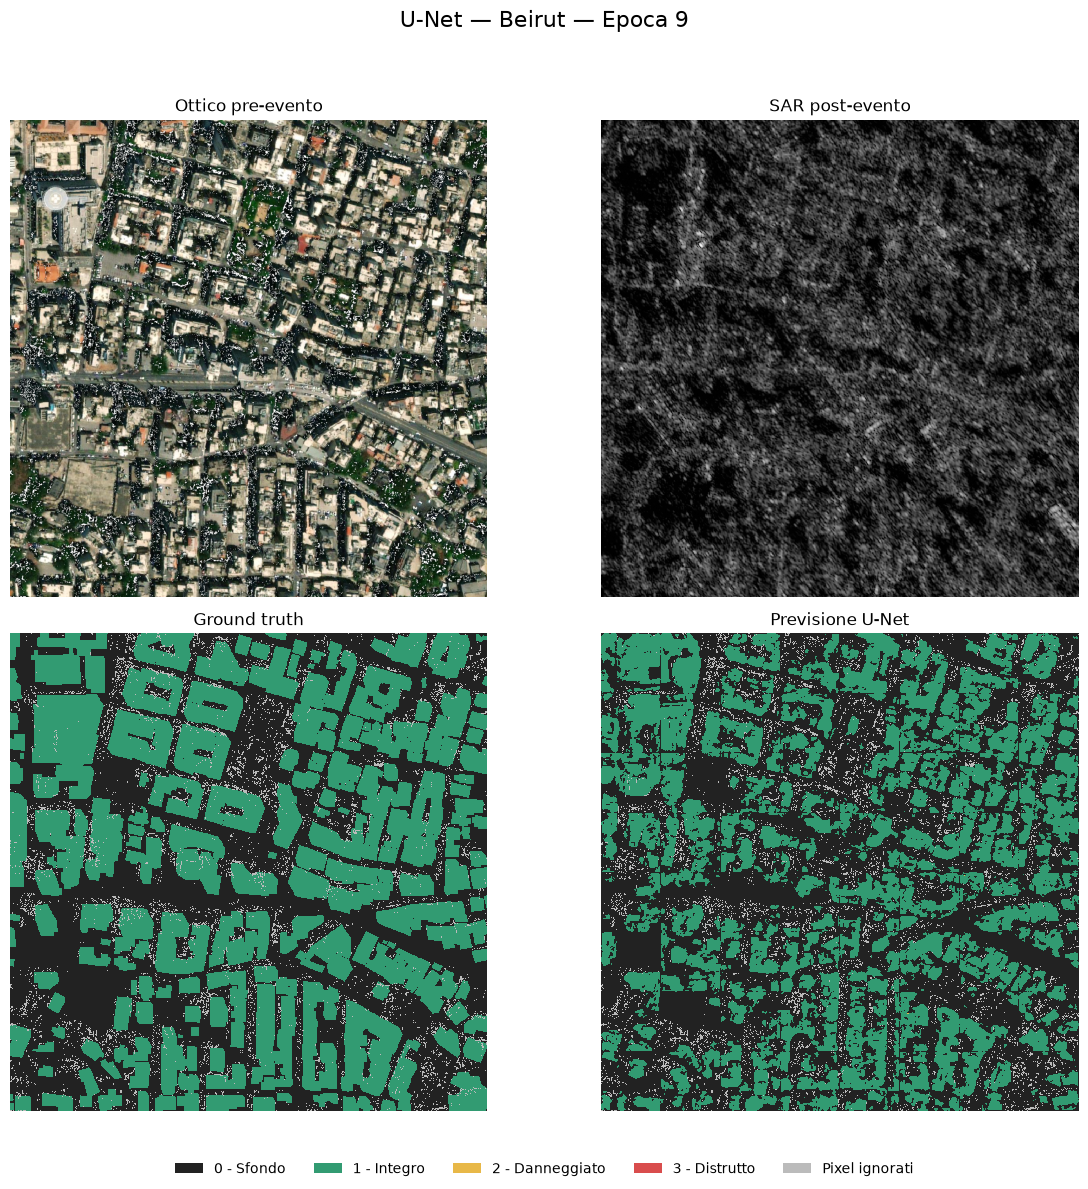

Figura salvata: /Users/antonyogrossi/tesi/riproduzione_dfc2025/risultati/04_baseline_unet/figure/beirut_previsione_epoca_09.png


In [37]:
import matplotlib.pyplot as plt

from bright_reproduction.visualization import (
    visualizza_previsione_immagine
)

fig_beirut = visualizza_previsione_immagine(
    CARTELLA_BASELINE / "val",
    risultato_inferenza,
    titolo=f"U-Net — Beirut — Epoca {epoca_migliore}",
    ignore_index=dataset_val.ignore_index
)

CARTELLA_FIGURE_BASELINE = (
    CARTELLA_RISULTATI_BASELINE / "figure"
)

CARTELLA_FIGURE_BASELINE.mkdir(
    parents=True,
    exist_ok=True
)

percorso_figura = (
    CARTELLA_FIGURE_BASELINE
    / f"beirut_previsione_epoca_{epoca_migliore:02d}.png"
)

fig_beirut.savefig(
    percorso_figura,
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figura salvata:", percorso_figura)

## Inferenza su un esempio con danni reali

Selezioniamo l'immagine di validation con il maggior
numero di pixel validi appartenenti alle classi
danneggiato e distrutto.

La selezione si basa esclusivamente sulle annotazioni,
non sulle prestazioni del modello.

In [38]:
from bright_reproduction.data import statistiche_patch

statistiche_patch_val = statistiche_patch(dataset_val)

distribuzione_val = (
    statistiche_patch_val
    .groupby("id")[colonne_classi]
    .sum()
)

distribuzione_val["totale_danni"] = (
    distribuzione_val["danneggiato"]
    + distribuzione_val["distrutto"]
)

distribuzione_val = distribuzione_val.sort_values(
    "totale_danni",
    ascending=False
)

display(distribuzione_val)

id_danni = distribuzione_val.index[0]

assert distribuzione_val.loc[id_danni, "totale_danni"] > 0

print("Immagine selezionata:", id_danni)

,sfondo,integro,danneggiato,distrutto,totale_danni
id,,,,,
hawaii-wildfire_00000002,921897,48468,7874,70337,78211
libya-flood_00000017,776161,0,17061,0,17061
haiti-earthquake_00000059,627801,406338,8672,2663,11335
bata-explosion_00000012,63395,11010,0,0,0
beirut-explosion_00000047,463344,542131,0,0,0
congo-volcano_00000014,1012136,740,0,0,0
la_palma-volcano_00000691,1031143,0,0,0,0
morocco-earthquake_00000448,1003324,0,0,0,0
turkey-earthquake_00000845,758837,289508,0,0,0


Immagine selezionata: hawaii-wildfire_00000002


In [39]:
risultato_danni = predici_immagine(
    modello_migliore,
    dataset_val,
    id_danni,
    device,
    batch_size=4
)

matrice_danni, tabella_danni, riepilogo_danni = (
    valuta_previsione(
        risultato_danni["riferimento"],
        risultato_danni["previsione"],
        dataset_val.ignore_index
    )
)

display(tabella_danni.round(4))

display(
    (pd.Series(riepilogo_danni) * 100).round(2)
)

assert (
    matrice_danni.sum()
    == risultato_danni["validita"].sum()
)

,Pixel reali,Pixel predetti,IoU,F1
Classe,,,,
Sfondo,921897,1007483,0.8999,0.9473
Integro,48468,41093,0.2390,0.3858
Danneggiato,7874,0,0.0000,0.0000
Distrutto,70337,0,0.0000,0.0000


Accuracy                88.80
mIoU diagnostica        28.47
mIoU 4 classi           28.47
mIoU classi presenti    28.47
F1 edificio             39.40
dtype: float64

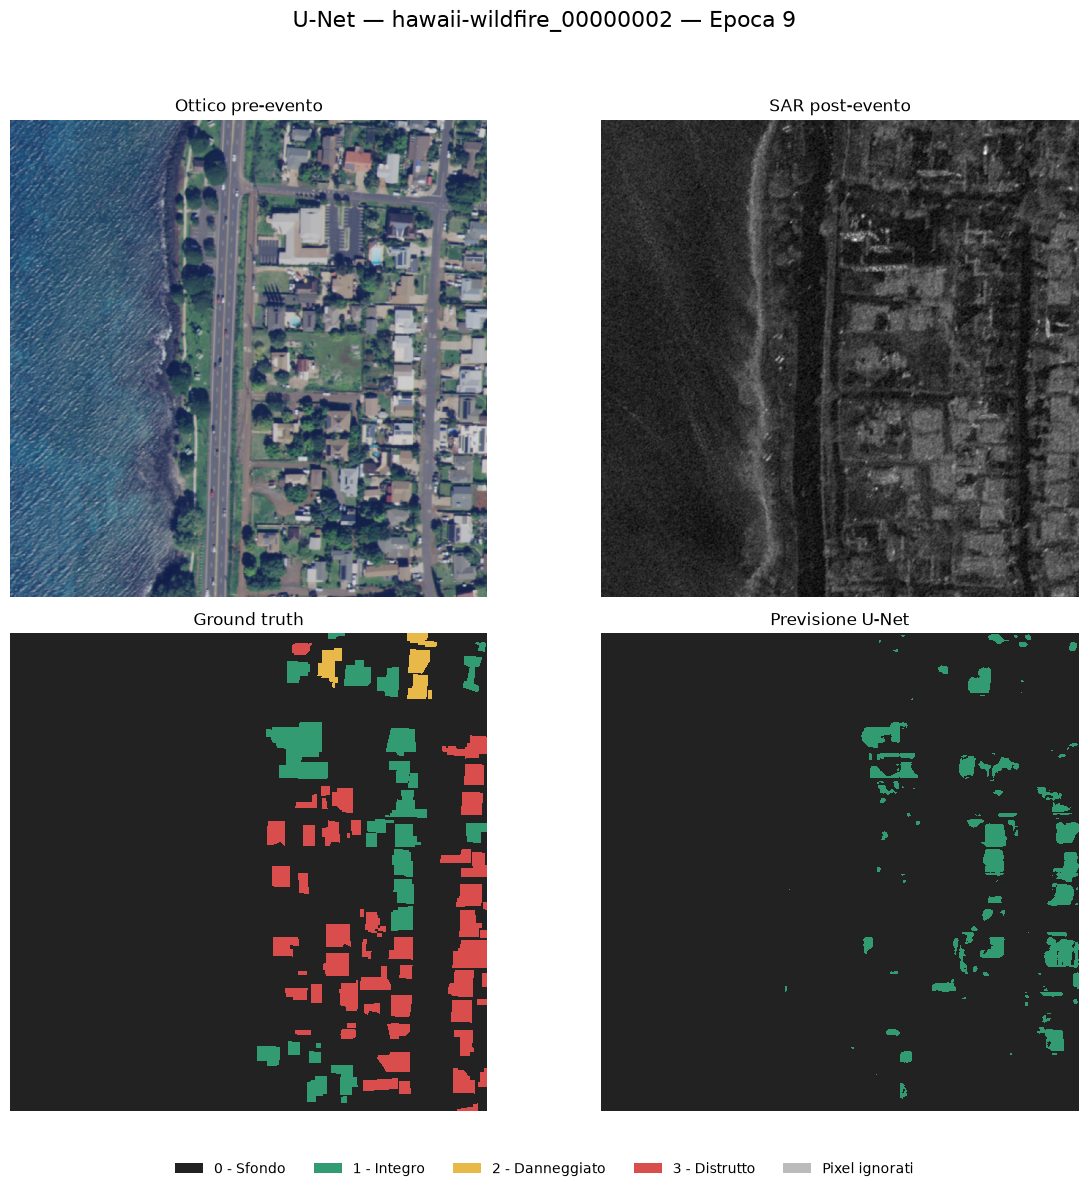

Figura salvata: /Users/antonyogrossi/tesi/riproduzione_dfc2025/risultati/04_baseline_unet/figure/hawaii-wildfire_00000002_previsione_epoca_09.png


In [40]:
fig_danni = visualizza_previsione_immagine(
    CARTELLA_BASELINE / "val",
    risultato_danni,
    titolo=f"U-Net — {id_danni} — Epoca {epoca_migliore}",
    ignore_index=dataset_val.ignore_index
)

percorso_figura_danni = (
    CARTELLA_FIGURE_BASELINE
    / f"{id_danni}_previsione_epoca_{epoca_migliore:02d}.png"
)

fig_danni.savefig(
    percorso_figura_danni,
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figura salvata:", percorso_figura_danni)

## Curve di apprendimento della baseline

Visualizziamo l'andamento delle loss e delle
metriche diagnostiche durante le dieci epoche
di addestramento.

Evidenziamo l'epoca migliore secondo la mIoU
di validation, corrispondente al checkpoint
utilizzato per le previsioni precedenti.

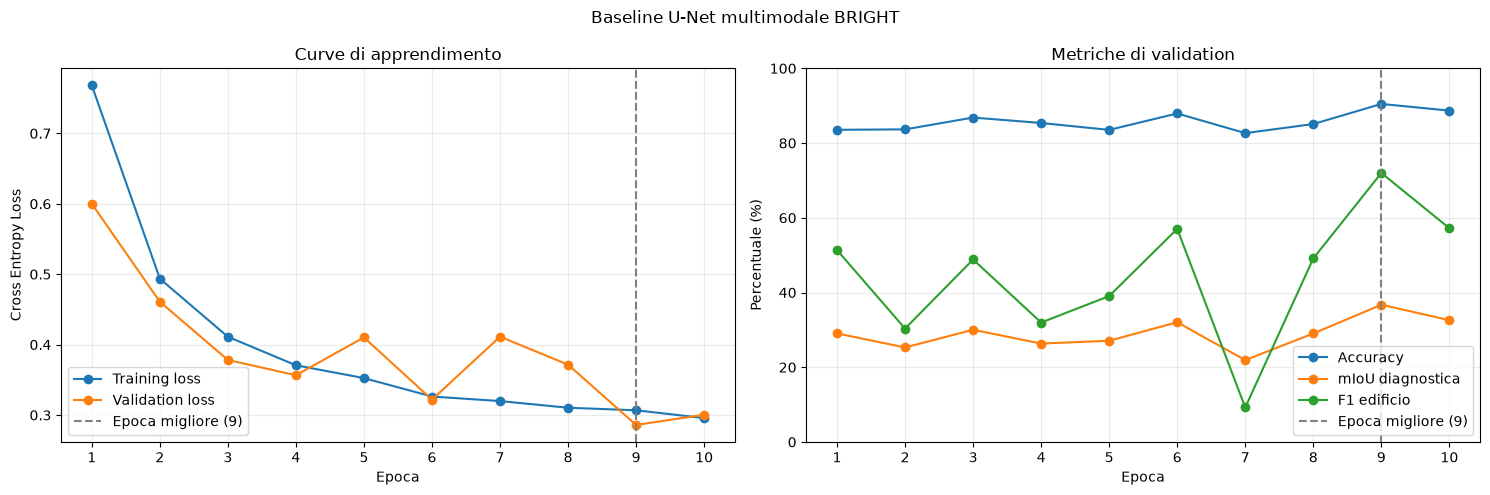

Figura salvata: /Users/antonyogrossi/tesi/riproduzione_dfc2025/risultati/04_baseline_unet/figure/curve_addestramento.png


In [41]:
from bright_reproduction.visualization import (
    visualizza_storico_addestramento
)

fig_storico = visualizza_storico_addestramento(
    storico_baseline
)

percorso_storico = (
    CARTELLA_FIGURE_BASELINE
    / "curve_addestramento.png"
)

fig_storico.savefig(
    percorso_storico,
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figura salvata:", percorso_storico)